# Phase 4 — Baseline Recommendation Models

## Objectives
- Implement Popularity, MF-BPR and LightGCN.
- Train using the Train temporal split.
- Evaluate using full-ranking on Validation.
- Report Precision@10, Recall@10 and NDCG@10.
- Save checkpoints and training histories.

**Environment:** Windows 11, VS Code, local `.venv`.

**Scope:** Baseline development and validation only.
No official Test evaluation.

Thiết lập môi trường

In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

def find_project_root():
    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (
            (candidate / "configs" / "baselines.yaml").exists()
            and (candidate / "src" / "models").is_dir()
        ):
            return candidate

    raise FileNotFoundError("Project root not found")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULT_DIR = PROJECT_ROOT / "experiments" / "phase4"

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Project:", PROJECT_ROOT)
print("CUDA:", torch.cuda.is_available())

Python: e:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
Project: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender
CUDA: False


Chạy huấn luyện

In [2]:
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "scripts/train_baselines.py"
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0, (
    "Baseline training failed"
)

print("Baseline training: PASSED")

Epoch 001 | Loss: 0.69305 | NDCG@10: 0.03464
Epoch 002 | Loss: 0.68556 | NDCG@10: 0.04293
Epoch 003 | Loss: 0.62409 | NDCG@10: 0.03527
Epoch 004 | Loss: 0.50226 | NDCG@10: 0.03638
Epoch 005 | Loss: 0.39714 | NDCG@10: 0.03342
Epoch 006 | Loss: 0.33717 | NDCG@10: 0.03346
Epoch 007 | Loss: 0.30536 | NDCG@10: 0.03256
Epoch 008 | Loss: 0.28618 | NDCG@10: 0.03362
Epoch 009 | Loss: 0.27896 | NDCG@10: 0.03705
Early stopping triggered
Epoch 001 | Loss: 0.69312 | NDCG@10: 0.00000
Epoch 002 | Loss: 0.69312 | NDCG@10: 0.00000
Epoch 003 | Loss: 0.69312 | NDCG@10: 0.00746
Epoch 004 | Loss: 0.69311 | NDCG@10: 0.01447
Epoch 005 | Loss: 0.69309 | NDCG@10: 0.01700
Epoch 006 | Loss: 0.69306 | NDCG@10: 0.02226
Epoch 007 | Loss: 0.69301 | NDCG@10: 0.01854
Epoch 008 | Loss: 0.69293 | NDCG@10: 0.03863
Epoch 009 | Loss: 0.69282 | NDCG@10: 0.03540
Epoch 010 | Loss: 0.69267 | NDCG@10: 0.03529
Epoch 011 | Loss: 0.69248 | NDCG@10: 0.03549
Epoch 012 | Loss: 0.69222 | NDCG@10: 0.03591
Epoch 013 | Loss: 0.69191 | ND

Đọc kết quả Validation

In [3]:
results = pd.read_csv(
    RESULT_DIR / "validation_results.csv"
)

display(results)

,model,users_evaluated,Precision@10,Recall@10,NDCG@10
0,Popularity,21,0.023810,0.039636,0.033860
1,MF-BPR,21,0.028571,0.039925,0.042932
2,LightGCN,21,0.033333,0.043588,0.038634


Biểu đồ so sánh ba baseline

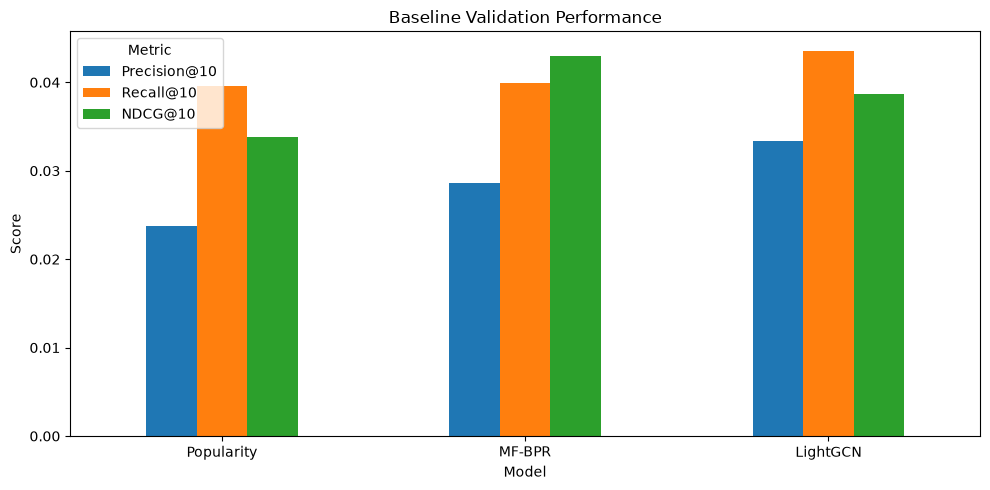

In [4]:
metrics = [
    "Precision@10",
    "Recall@10",
    "NDCG@10"
]

ax = results.set_index("model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Baseline Validation Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(title="Metric")

plt.tight_layout()
plt.show()

Đọc lịch sử huấn luyện

In [5]:
with open(
    RESULT_DIR / "training_history.json",
    encoding="utf-8"
) as f:
    training_history = json.load(f)

for model_name, history in training_history.items():
    print(model_name)
    display(pd.DataFrame(history).tail())

MF-BPR


,epoch,loss,val_precision,val_recall,val_ndcg
4,5,0.397143,0.023810,0.039636,0.033421
5,6,0.337167,0.023810,0.039636,0.033459
6,7,0.305359,0.023810,0.039636,0.032564
7,8,0.286183,0.023810,0.039636,0.033621
8,9,0.278956,0.028571,0.040552,0.037049


LightGCN


,epoch,loss,val_precision,val_recall,val_ndcg
10,11,0.692477,0.028571,0.039925,0.035490
11,12,0.692225,0.028571,0.039925,0.035911
12,13,0.691914,0.028571,0.039925,0.036308
13,14,0.691531,0.023810,0.039636,0.035097
14,15,0.691064,0.023810,0.039636,0.036376


Biểu đồ Training Loss

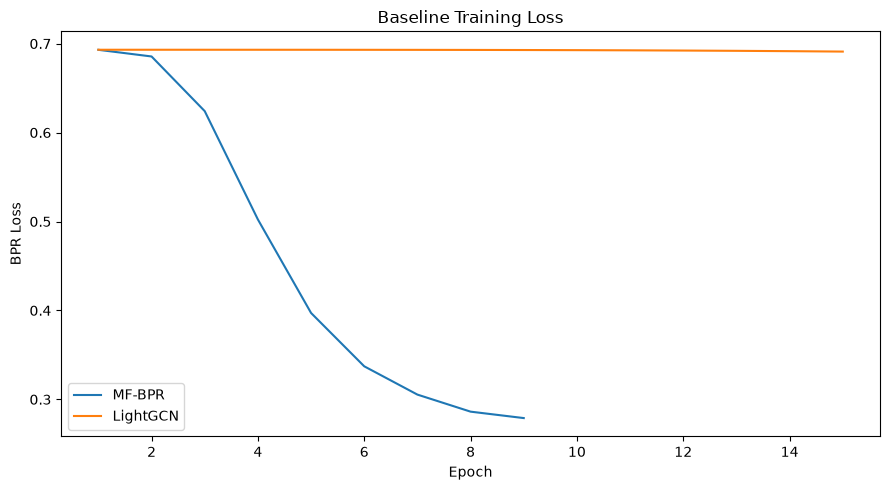

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, history in training_history.items():
    df = pd.DataFrame(history)

    ax.plot(
        df["epoch"],
        df["loss"],
        label=model_name
    )

ax.set_title("Baseline Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("BPR Loss")
ax.legend()

plt.tight_layout()
plt.show()

Biểu đồ Validation NDCG@10

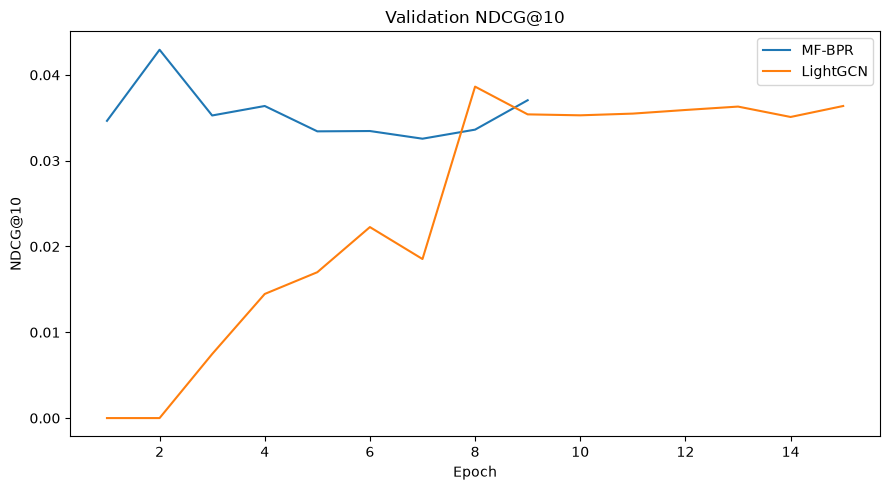

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, history in training_history.items():
    df = pd.DataFrame(history)

    ax.plot(
        df["epoch"],
        df["val_ndcg"],
        label=model_name
    )

ax.set_title("Validation NDCG@10")
ax.set_xlabel("Epoch")
ax.set_ylabel("NDCG@10")
ax.legend()

plt.tight_layout()
plt.show()

Xác định mô hình có Validation NDCG tốt nhất

In [8]:
best_model = results.sort_values(
    "NDCG@10",
    ascending=False
).iloc[0]

print("Best baseline:", best_model["model"])
print("NDCG@10:", best_model["NDCG@10"])
print("Recall@10:", best_model["Recall@10"])
print("Precision@10:", best_model["Precision@10"])

Best baseline: MF-BPR
NDCG@10: 0.042932367749297
Recall@10: 0.0399248899248899
Precision@10: 0.0285714285714285


Kiểm thử

In [9]:
result = subprocess.run(
    [
        sys.executable,
        "-m",
        "unittest",
        "discover",
        "-s",
        "tests",
        "-p",
        "test_baselines.py",
        "-v"
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0
print("Phase 4 unit tests: PASSED")


test_bpr_loss (test_baselines.TestBaselines.test_bpr_loss) ... ok
test_full_ranking_filters_history (test_baselines.TestBaselines.test_full_ranking_filters_history) ... ok
test_lightgcn_output_shape (test_baselines.TestBaselines.test_lightgcn_output_shape) ... ok
test_mf_output_shape (test_baselines.TestBaselines.test_mf_output_shape) ... ok
test_negative_sampling (test_baselines.TestBaselines.test_negative_sampling) ... ok
test_popularity (test_baselines.TestBaselines.test_popularity) ... ok
test_ranking_metrics (test_baselines.TestBaselines.test_ranking_metrics) ... ok

----------------------------------------------------------------------
Ran 7 tests in 0.020s

OK

Phase 4 unit tests: PASSED


Xuất báo cáo

In [10]:
report = {
    "phase": 4,
    "environment": "local",
    "dataset": "MovieLens Latest Small",
    "models": results.to_dict(orient="records"),
    "best_validation_model": str(best_model["model"]),
    "selection_metric": "NDCG@10",
    "evaluation": "full-ranking",
    "test_evaluated": False,
    "unit_tests": "passed"
}

report_path = RESULT_DIR / "phase4_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(
        report,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Saved:", report_path)

Saved: E:\SV\NAM4-KY1\1. DSS\HGNN-Attention-Recommender\experiments\phase4\phase4_report.json


In [11]:
import pandas as pd

train = pd.read_csv(PROJECT_ROOT / "data/splits/train.csv")
val = pd.read_csv(PROJECT_ROOT / "data/splits/val.csv")
test = pd.read_csv(PROJECT_ROOT / "data/splits/test.csv")

evaluation_users = pd.read_csv(
    PROJECT_ROOT / "data/splits/evaluation_users.csv"
)

train_users = set(train["user_idx"])
val_users = set(val["user_idx"])
test_users = set(test["user_idx"])

train_positive = set(
    train.loc[train["is_positive"] == 1, "user_idx"]
)

val_positive = set(
    val.loc[val["is_positive"] == 1, "user_idx"]
)

eligible = set(
    evaluation_users.loc[
        evaluation_users["eligible_val"] == True,
        "user_idx"
    ]
)

summary = pd.DataFrame({
    "Metric": [
        "Total users in dataset",
        "Users in Train",
        "Users in Validation",
        "Users in Test",
        "Users in both Train and Validation",
        "Users with positive Train interactions",
        "Users with positive Validation interactions",
        "Users with positives in both Train and Validation",
        "Eligible Validation users",
    ],
    "Count": [
        len(train_users | val_users | test_users),
        len(train_users),
        len(val_users),
        len(test_users),
        len(train_users & val_users),
        len(train_positive),
        len(val_positive),
        len(train_positive & val_positive),
        len(eligible),
    ]
})

display(summary)

,Metric,Count
0,Total users in dataset,610
1,Users in Train,522
2,Users in Validation,62
3,Users in Test,74
4,Users in both Train and Validation,21
5,Users with positive Train interactions,521
6,Users with positive Validation interactions,62
7,Users with positives in both Train and Validation,21
8,Eligible Validation users,21
